<a href="https://colab.research.google.com/github/Jainwinsarthak/rf-pm-sensing/blob/main/Final_year_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np   # import lib and define no of sample to be gen
import matplotlib.pyplot as plt
n = 10000

In [18]:
#genert wireless channel cofficent
rng = np.random.default_rng(42)
h_real = rng.normal(0, 1, n)
h_imag = rng.normal(0, 1, n)
h = h_real + 1j * h_imag
#print("Actual channel:", h)

In [19]:
x = 1 + 1j  # Define transmited signal

In [20]:
channel_variance=2.0

snr_db =np.arange(0,26)

mse_zfm=[]
mse_mmse=[]

In [21]:
noise_real = rng.normal(0,1,n)  #(means,sd,value)
noise_imag = 1j*rng.normal(0, 1, n)
noise_unit =(noise_real+noise_imag)/np.sqrt(2) #cal noise unit

In [22]:
for snr in snr_db:
  snr_linear = 10**(snr/10)
  noise_variance =1 /snr_linear
  noise= np.sqrt(noise_variance)*noise_unit


#synthesising the channekl at reciver
  y = h * x + noise

#define the zfm formula
  h_zfm = y / x
#define the mmse formula
  h_mmse=(channel_variance*np.conj(x)/(channel_variance * np.abs(x)**2 + noise_variance))*y

  mse_zfm.append(np.mean(np.abs(h_zfm - h)**2))             #add value of mse in list
  mse_mmse.append(np.mean(np.abs(h_mmse - h)**2))

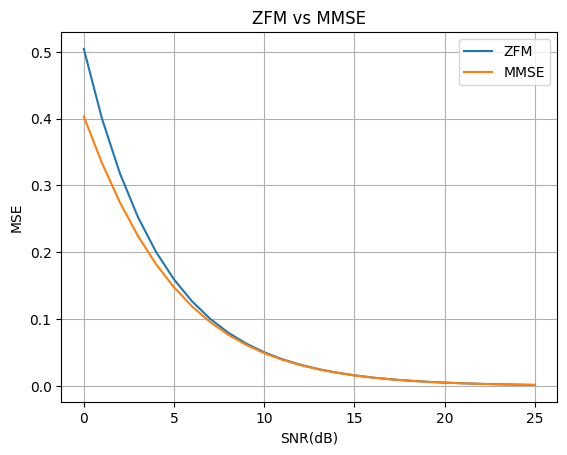

In [23]:
plt.plot(snr_db,mse_zfm,label="ZFM")           #plot graoph for both
plt.plot(snr_db,mse_mmse,label="MMSE")

plt.xlabel("SNR(dB)")
plt.ylabel("MSE")
plt.title("ZFM vs MMSE")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
print("SNR|ZFM MSE|MMSE MSE|DIFF (%)")  #comapring the zfm and mmse improv in result

for snr,zfm,mmse in zip(snr_db,  mse_zfm,  mse_mmse):
    diff =(zfm-mmse)/zfm*100
    print(f"{snr:2d} |{zfm:.6f}|{mmse:.6f}|{diff:.2f}%")

SNR|ZFM MSE|MMSE MSE|DIFF (%)
 0 |0.504339|0.403089|20.08%
 1 |0.400611|0.333938|16.64%
 2 |0.318217|0.274629|13.70%
 3 |0.252768|0.224448|11.20%
 4 |0.200781|0.182475|9.12%
 5 |0.159486|0.147704|7.39%
 6 |0.126684|0.119127|5.97%
 7 |0.100629|0.095795|4.80%
 8 |0.079932|0.076848|3.86%
 9 |0.063493|0.061527|3.09%
10 |0.050434|0.049184|2.48%
11 |0.040061|0.039267|1.98%
12 |0.031822|0.031317|1.59%
13 |0.025277|0.024957|1.27%
14 |0.020078|0.019875|1.01%
15 |0.015949|0.015820|0.81%
16 |0.012668|0.012587|0.65%
17 |0.010063|0.010011|0.52%
18 |0.007993|0.007960|0.41%
19 |0.006349|0.006328|0.33%
20 |0.005043|0.005030|0.26%
21 |0.004006|0.003998|0.21%
22 |0.003182|0.003177|0.17%
23 |0.002528|0.002524|0.13%
24 |0.002008|0.002006|0.11%
25 |0.001595|0.001593|0.09%
